In [10]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

cst = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
cst = cst[cst.regionname == 'CST_R']

# contra, ipsilesional cerebellum
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_Nettekoven_LeftRight_FaMap.tsv'), sep = '\t')
cerebel = cerebel[cerebel.regionname == 'cerebellum_L']

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0

week 0: r = -0.22033476789524717, p-value = 0.36471024651555733
week 4: r = -0.5461293908757711, p-value = 0.0070184867475322
week 12: r = -0.3188567645459474, p-value = 0.12029586110327779
week 24: r = -0.5638668128659652, p-value = 0.006273108391109735
week 52: r = -0.03784155330821787, p-value = 0.917340037598455


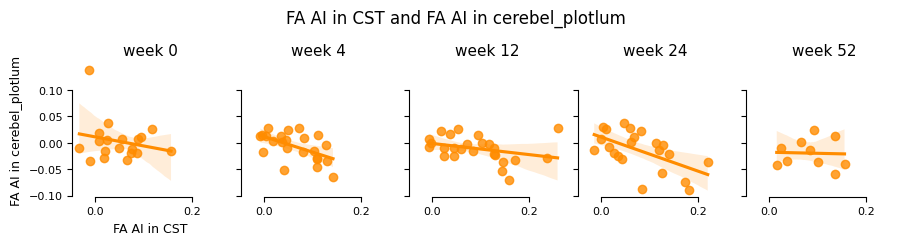

In [11]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    cerebel_plot = cerebel[cerebel.Week == week]
    cst_plot = cst[cst.Week == week]
    cerebel_cst_plot = pd.merge(cst_plot, cerebel_plot, on = ['subj_id', 'Week'], how = 'inner', suffixes = ('_cst', '_cerebel_plot'))

    r_stat, p_stat = stats.pearsonr(cerebel_cst_plot['asymmetry_index_cerebel_plot'],cerebel_cst_plot['asymmetry_index_cst'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index_cst', y = 'asymmetry_index_cerebel_plot', data = cerebel_cst_plot, ax = ax, color = 'darkorange') # see what happens when switch x, y
    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')

axs[0].set_ylabel("FA AI in cerebel_plotlum")
axs[0].set_xlabel(f"FA AI in CST")
fig.suptitle(f"FA AI in CST and FA AI in cerebel_plotlum", y = 1.15)
sns.despine(trim = True)
plt.show()

week 0: r = -0.07474166764914322, p-value = 0.7755727013996254
week 4: r = 0.3706373381489051, p-value = 0.08949665983614262
week 12: r = 0.22287584627604745, p-value = 0.2951841661173329
week 24: r = 0.15605470157010412, p-value = 0.49935825054324506
week 52: r = 0.31898155283202667, p-value = 0.3689962556524


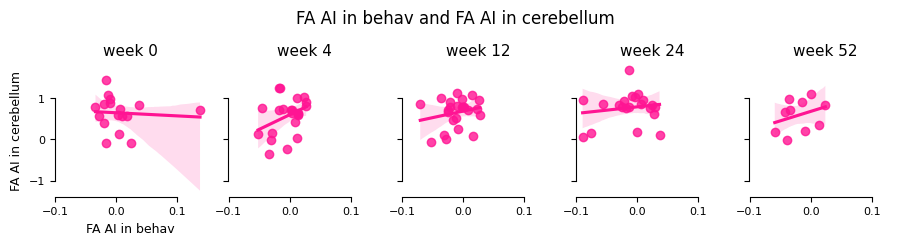

In [12]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    cerebel_plot = cerebel[cerebel.Week == week]
    behav_plot = behav[behav.Week == week]
    cerebel_behav_plot = pd.merge(behav_plot, cerebel_plot, on = ['subj_id', 'Week'], how = 'inner', suffixes = ('_behav', '_cerebel'))

    r_stat, p_stat = stats.pearsonr(cerebel_behav_plot['asymmetry_index'],cerebel_behav_plot['indiv_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

    ax = axs[i]
    sns.regplot(y = 'indiv_norm', x = 'asymmetry_index', data = cerebel_behav_plot, ax = ax, color = 'deeppink') # see what happens when switch x, y
    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')

axs[0].set_ylabel("FA AI in cerebellum")
axs[0].set_xlabel(f"FA AI in behav")
fig.suptitle(f"FA AI in behav and FA AI in cerebellum", y = 1.15)
sns.despine(trim = True)
plt.show()

week 0: r = 0.09593871413941552, p-value = 0.7141546699933816
week 4: r = 0.32686082764944513, p-value = 0.1376079050456458
week 12: r = 0.09392412174448637, p-value = 0.6624478702334236
week 24: r = 0.09290028947284909, p-value = 0.6887718248114036
week 52: r = 0.023104838217186285, p-value = 0.949485138685415


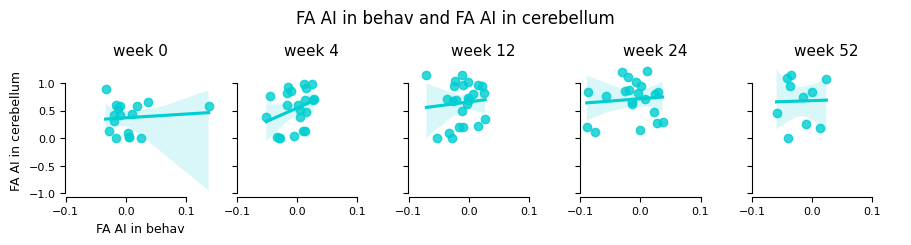

In [13]:
# fa asymmetry (cerebellum) and strength

fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    cerebel_plot = cerebel[cerebel.Week == week]
    behav_plot = behav[behav.Week == week]
    cerebel_behav_plot = pd.merge(behav_plot, cerebel_plot, on = ['subj_id', 'Week'], how = 'inner', suffixes = ('_behav', '_cerebel'))

    r_stat, p_stat = stats.pearsonr(cerebel_behav_plot['asymmetry_index'],cerebel_behav_plot['mvc_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

    ax = axs[i]
    sns.regplot(y = 'mvc_norm', x = 'asymmetry_index', data = cerebel_behav_plot, ax = ax, color = 'darkturquoise') # see what happens when switch x, y
    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')

axs[0].set_ylabel("FA AI in cerebellum")
axs[0].set_xlabel(f"FA AI in behav")
fig.suptitle(f"FA AI in behav and FA AI in cerebellum", y = 1.15)
sns.despine(trim = True)
plt.show()

In [14]:
# FISHER Z TRANSFORM - INDIVIDUATION
rows_indiv = []
for week in gl.weeks:
    cerebel_week_plot = cerebel[cerebel.Week == week]
    cerebel_plot = cerebel_week_plot.groupby(['subj_id'], as_index = False)['asymmetry_index'].mean()
    behav_plot = behav[(behav.Week == week)].groupby('subj_id', as_index = False)['indiv_norm'].mean()
    behav_cerebel = pd.merge(behav_plot, cerebel_plot, on = ['subj_id'], how = 'inner', suffixes = ('_behav', '_cerebel'))
    
    r_stat, p_val = stats.pearsonr(behav_cerebel['asymmetry_index'], behav_cerebel['indiv_norm']) # use fitted value from piecewise function, y_hat

    n = len(behav_cerebel.subj_id.unique())
    z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
    lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
    rows_indiv.append({'Week': week, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
rdf_indiv = pd.DataFrame(rows_indiv)

In [15]:
# FISHER Z TRANSFORM - STRENGTH
rows_mvc = []
for week in gl.weeks:
    cerebel_week_plot = cerebel[cerebel.Week == week]
    cerebel_plot = cerebel_week_plot.groupby(['subj_id'], as_index = False)['asymmetry_index'].mean()
    behav_plot = behav[(behav.Week == week)].groupby('subj_id', as_index = False)['mvc_norm'].mean()
    behav_cerebel = pd.merge(behav_plot, cerebel_plot, on = ['subj_id'], how = 'inner', suffixes = ('_behav', '_cerebel'))
    
    r_stat, p_val = stats.pearsonr(behav_cerebel['asymmetry_index'], behav_cerebel['mvc_norm']) # use fitted value from piecewise function, y_hat

    n = len(behav_cerebel.subj_id.unique())
    z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
    lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
    rows_mvc.append({'Week': week, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
rdf_mvc = pd.DataFrame(rows_mvc)

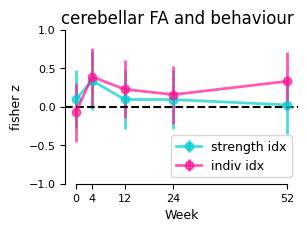

In [16]:
fig, ax = plt.subplots(figsize = (3,2))

# strength
ax.errorbar(x = rdf_mvc['Week'], y = rdf_mvc['z'], yerr = se,              
marker = 'o', linestyle = '-', linewidth = 2, color = 'darkturquoise', alpha = .7, label = 'strength idx')

# individuation
ax.errorbar(x = rdf_indiv['Week'], y = rdf_indiv['z'], yerr = se,              
marker = 'o', linestyle = '-', linewidth = 2, color = 'deeppink', alpha = .7, label = 'indiv idx')


ax.set_xticks(gl.weeks)
ax.set_xlabel('Week')
ax.set_ylabel('fisher z')
plt.legend(loc = 'lower right')
plt.suptitle("cerebellar FA and behaviour")
ax.set_ylim(-1, 1)
plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
sns.despine(trim = True)
plt.show()